In [2]:
import os
import sys
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import shap

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    accuracy_score, precision_score, recall_score,
    balanced_accuracy_score, matthews_corrcoef, confusion_matrix,
    roc_curve, precision_recall_curve
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("[1] Environment initialized with fixed random seed (42).")


[1] Environment initialized with fixed random seed (42).


In [4]:
DATASET_FILENAME = "lung_cancer_risk.csv"

df = pd.read_csv(DATASET_FILENAME)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(5)


Dataset Shape: 50100 rows, 20 columns


,age,sex,race,education,bmi,smoking_status,cigarettes_per_day,years_smoked,pack_years,years_since_quit,copd,emphysema,chronic_bronchitis,personal_cancer_history,family_lung_cancer,occupational_exposure,secondhand_smoke,alcohol_use,screening_history,lung_cancer
0,52,Female,Other,Some College,35.9,Former,16.0,20.7,16.6,5.0,No,No,No,No,No,No,No,Yes,No,0
1,73,Female,White,Some College,23.1,Current,8.0,42.8,17.1,0.0,No,No,Yes,No,No,No,Yes,No,No,0
2,70,Female,Asian,Some College,28.8,Current,31.0,31.0,48.0,0.0,No,No,Yes,No,No,No,No,No,No,0
3,63,Male,Asian,Some College,30.9,Former,7.0,24.9,8.7,14.0,Yes,No,No,No,No,No,Yes,No,No,0
4,63,Male,Black,College or Higher,31.8,Former,18.0,38.5,34.6,15.0,No,No,No,No,No,No,No,No,Yes,0


In [5]:
TARGET = "lung_cancer"
assert TARGET in df.columns, f"Target column '{TARGET}' missing."

target_counts = df[TARGET].value_counts()
target_pct = df[TARGET].value_counts(normalize=True) * 100

print(f"Target Variable '{TARGET}' Breakdown:")
for cls_val in target_counts.index:
    print(f"  Class {cls_val}: {target_counts[cls_val]:,d} samples ({target_pct[cls_val]:.2f}%)")

print("\nMissing Value Audit:")
missing = df.isnull().sum()
if missing.sum() == 0:
    print("  No missing values detected.")
else:
    print(missing[missing > 0])


Target Variable 'lung_cancer' Breakdown:
  Class 0: 48,718 samples (97.24%)
  Class 1: 1,382 samples (2.76%)

Missing Value Audit:
education                471
bmi                      757
cigarettes_per_day       505
years_smoked             511
years_since_quit         465
family_lung_cancer       559
occupational_exposure    371
dtype: int64


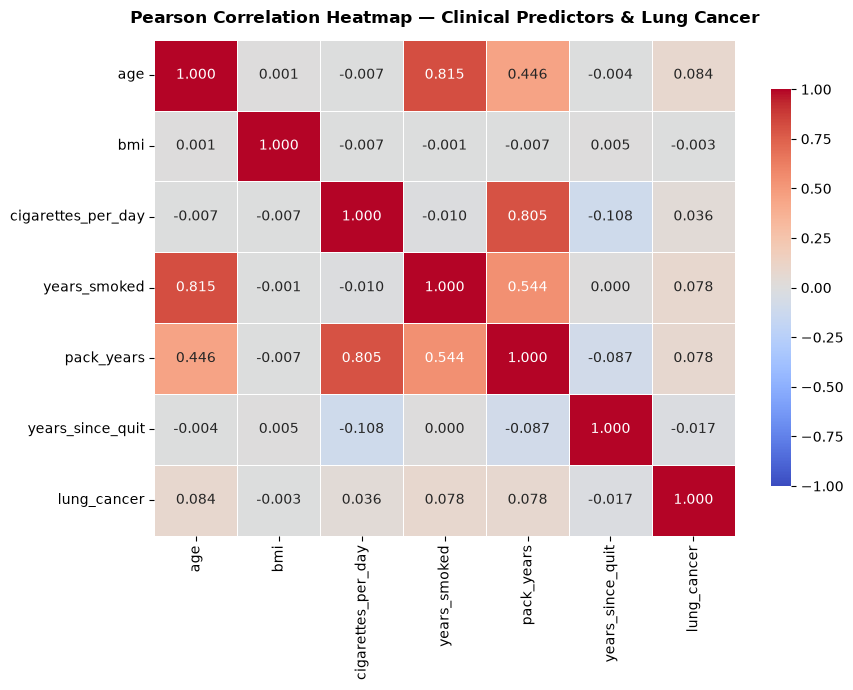

In [6]:
import seaborn as sns

# Compute correlation matrix for continuous features + target
corr_cols = ["age", "bmi", "cigarettes_per_day", "years_smoked", "pack_years", "years_since_quit", "lung_cancer"]
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Pearson Correlation Heatmap — Clinical Predictors & Lung Cancer", fontsize=12, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()


In [7]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

# Split 85% trainval, 15% test
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=RANDOM_STATE
)

# Split trainval into 70% train and 15% validation
val_fraction = 0.15 / 0.85
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=val_fraction,
    stratify=y_trainval, random_state=RANDOM_STATE
)

print(f"Train Set      : {len(X_train):,d} rows ({len(X_train)/len(df)*100:.1f}%) | Pos Rate: {y_train.mean()*100:.2f}%")
print(f"Validation Set : {len(X_val):,d} rows ({len(X_val)/len(df)*100:.1f}%) | Pos Rate: {y_val.mean()*100:.2f}%")
print(f"Test Set       : {len(X_test):,d} rows ({len(X_test)/len(df)*100:.1f}%) | Pos Rate: {y_test.mean()*100:.2f}%")

# Integrity Assertion: Disjoint indices
assert len(set(X_train.index) & set(X_val.index)) == 0
assert len(set(X_train.index) & set(X_test.index)) == 0
assert len(set(X_val.index) & set(X_test.index)) == 0
print("Index integrity verification passed: All partitions are strictly disjoint.")


Train Set      : 35,069 rows (70.0%) | Pos Rate: 2.76%
Validation Set : 7,516 rows (15.0%) | Pos Rate: 2.75%
Test Set       : 7,515 rows (15.0%) | Pos Rate: 2.75%
Index integrity verification passed: All partitions are strictly disjoint.


In [ ]:
num_features = ["age", "bmi", "cigarettes_per_day", "years_smoked", "pack_years", "years_since_quit"]
cat_features = [
    "sex", "race", "education", "smoking_status", "copd", "emphysema",
    "chronic_bronchitis", "personal_cancer_history", "family_lung_cancer",
    "occupational_exposure", "secondhand_smoke", "alcohol_use", "screening_history"
]

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_features),
    ("cat", cat_pipeline, cat_features),
])

# Fit ONLY on training data
X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc   = preprocessor.transform(X_val)
X_test_proc  = preprocessor.transform(X_test)

ohe_encoder = preprocessor.named_transformers_["cat"]["encoder"]
encoded_cat_names = ohe_encoder.get_feature_names_out(cat_features).tolist()
all_feature_names = num_features + encoded_cat_names
    
print(f"Processed Feature Count: {len(all_feature_names)}")
print(f"Continuous Features    : {len(num_features)}")
print(f"One-Hot Encoded Dims   : {len(encoded_cat_names)}")
assert X_train_proc.shape[1] == len(all_feature_names)
assert not np.isnan(X_train_proc).any()


Processed Feature Count: 37
Continuous Features    : 6
One-Hot Encoded Dims   : 31


In [9]:
lr = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    solver="lbfgs"
)
lr.fit(X_train_proc, y_train)

lr_prob_train = lr.predict_proba(X_train_proc)[:, 1]
lr_prob_val   = lr.predict_proba(X_val_proc)[:, 1]
lr_prob_test  = lr.predict_proba(X_test_proc)[:, 1]

lr_val_auc = roc_auc_score(y_val, lr_prob_val)
lr_test_auc = roc_auc_score(y_test, lr_prob_test)

print(f"Logistic Regression Validation ROC-AUC : {lr_val_auc:.4f}")
print(f"Logistic Regression Test ROC-AUC       : {lr_test_auc:.4f}")


Logistic Regression Validation ROC-AUC : 0.7057
Logistic Regression Test ROC-AUC       : 0.6599


In [10]:
lgb_model = lgb.LGBMClassifier(
    n_estimators=100,
    max_depth=3,
    num_leaves=7,
    min_child_samples=100,
    learning_rate=0.05,
    subsample=0.7,
    subsample_freq=1,
    colsample_bytree=0.7,
    reg_alpha=2.0,
    reg_lambda=5.0,
    is_unbalance=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1
)

lgb_model.fit(X_train_proc, y_train)

lgb_prob_train = lgb_model.predict_proba(X_train_proc)[:, 1]
lgb_prob_val   = lgb_model.predict_proba(X_val_proc)[:, 1]
lgb_prob_test  = lgb_model.predict_proba(X_test_proc)[:, 1]

lgb_val_auc = roc_auc_score(y_val, lgb_prob_val)
lgb_test_auc = roc_auc_score(y_test, lgb_prob_test)

print(f"LightGBM Validation ROC-AUC : {lgb_val_auc:.4f}")
print(f"LightGBM Test ROC-AUC       : {lgb_test_auc:.4f}")


LightGBM Validation ROC-AUC : 0.7011
LightGBM Test ROC-AUC       : 0.6640


In [11]:
weights = np.round(np.arange(0.0, 1.01, 0.05), 2)
best_w = 0.5
best_val_auc = 0.0

for w in weights:
    blend_val = w * lr_prob_val + (1.0 - w) * lgb_prob_val
    auc = roc_auc_score(y_val, blend_val)
    if auc > best_val_auc:
        best_val_auc = auc
        best_w = float(w)

HYBRID_WEIGHT_LR = best_w
print(f"Optimal Logistic Regression Weight (w_lr) : {HYBRID_WEIGHT_LR:.2f}")
print(f"Optimal LightGBM Weight (w_lgb)           : {1.0 - HYBRID_WEIGHT_LR:.2f}")
print(f"Best Hybrid Validation ROC-AUC            : {best_val_auc:.4f}")

# Compute frozen test blend
hybrid_prob_val  = HYBRID_WEIGHT_LR * lr_prob_val + (1.0 - HYBRID_WEIGHT_LR) * lgb_prob_val
hybrid_prob_test = HYBRID_WEIGHT_LR * lr_prob_test + (1.0 - HYBRID_WEIGHT_LR) * lgb_prob_test
hybrid_test_auc  = roc_auc_score(y_test, hybrid_prob_test)
print(f"Hybrid Final Test ROC-AUC                 : {hybrid_test_auc:.4f}")


Optimal Logistic Regression Weight (w_lr) : 0.75
Optimal LightGBM Weight (w_lgb)           : 0.25
Best Hybrid Validation ROC-AUC            : 0.7068
Hybrid Final Test ROC-AUC                 : 0.6630


In [12]:
threshold_candidates = np.round(np.arange(0.10, 0.91, 0.01), 2)
best_thresh = 0.5
best_f1 = 0.0

for t in threshold_candidates:
    preds = (hybrid_prob_val >= t).astype(int)
    f1 = f1_score(y_val, preds, zero_division=0)
    if f1 > best_f1:
        best_f1 = f1
        best_thresh = float(t)

DECISION_THRESHOLD = best_thresh
print(f"Selected Decision Threshold : {DECISION_THRESHOLD:.2f}")
print(f"Validation F1-Score         : {best_f1:.4f}")


Selected Decision Threshold : 0.67
Validation F1-Score         : 0.1253


In [13]:
y_pred_test = (hybrid_prob_test >= DECISION_THRESHOLD).astype(int)

metrics = {
    "Accuracy"          : accuracy_score(y_test, y_pred_test),
    "Precision"         : precision_score(y_test, y_pred_test, zero_division=0),
    "Recall (Sensitivity)" : recall_score(y_test, y_pred_test, zero_division=0),
    "F1-Score"          : f1_score(y_test, y_pred_test, zero_division=0),
    "Balanced Accuracy" : balanced_accuracy_score(y_test, y_pred_test),
    "ROC-AUC"           : roc_auc_score(y_test, hybrid_prob_test),
    "PR-AUC"            : average_precision_score(y_test, hybrid_prob_test),
    "MCC"               : matthews_corrcoef(y_test, y_pred_test),
}

print("="*45)
print("PULMOGUARD HYBRID MODEL — TEST SET METRICS")
print("="*45)
for k, v in metrics.items():
    print(f"  {k:22s} : {v:.4f}")
print("="*45)

cm = confusion_matrix(y_test, y_pred_test)
print(f"Confusion Matrix:\nTN: {cm[0,0]:,d} | FP: {cm[0,1]:,d}\nFN: {cm[1,0]:,d} | TP: {cm[1,1]:,d}")


PULMOGUARD HYBRID MODEL — TEST SET METRICS
  Accuracy               : 0.9046
  Precision              : 0.0663
  Recall (Sensitivity)   : 0.1884
  F1-Score               : 0.0981
  Balanced Accuracy      : 0.5566
  ROC-AUC                : 0.6630
  PR-AUC                 : 0.0507
  MCC                    : 0.0690
Confusion Matrix:
TN: 6,759 | FP: 549
FN: 168 | TP: 39


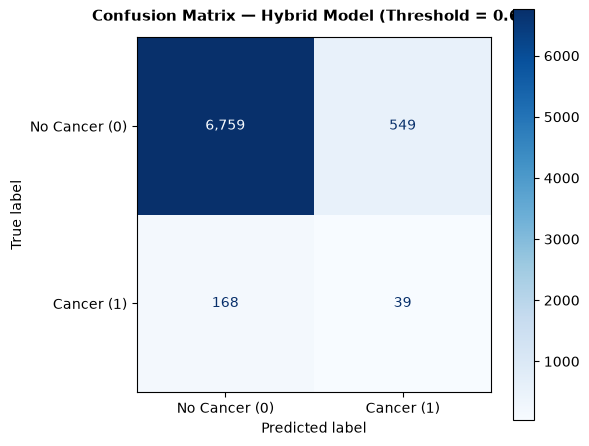

Specificity (TNR) : 0.9249 (6,759 / 7,308)
Sensitivity (TPR) : 0.1884 (39 / 207)
Precision (PPV)   : 0.0663 (39 / 588)


In [14]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Cancer (0)", "Cancer (1)"]
)
disp.plot(ax=ax, cmap="Blues", values_format=",d", colorbar=True)
plt.title(f"Confusion Matrix — Hybrid Model (Threshold = {DECISION_THRESHOLD:.2f})", fontsize=11, fontweight="bold", pad=12)
plt.grid(False)
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Specificity (TNR) : {tn / (tn + fp):.4f} ({tn:,d} / {tn+fp:,d})")
print(f"Sensitivity (TPR) : {tp / (tp + fn):.4f} ({tp:,d} / {tp+fn:,d})")
print(f"Precision (PPV)   : {tp / (tp + fp):.4f} ({tp:,d} / {tp+fp:,d})")


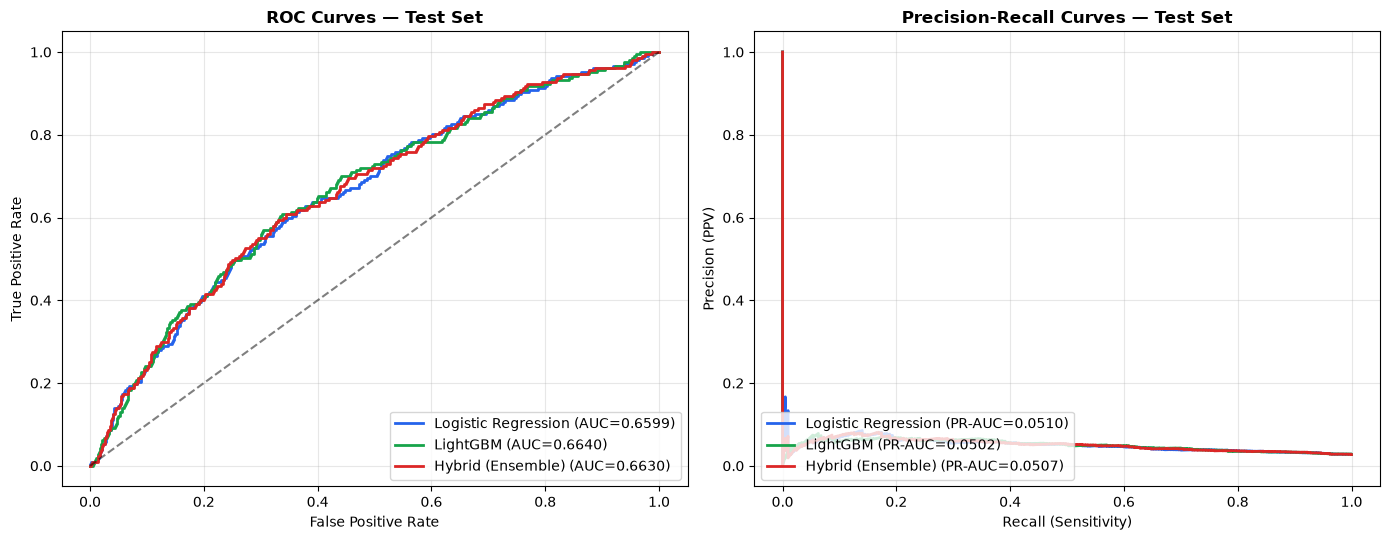

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# ROC Curves
for name, probs, color in [
    ("Logistic Regression", lr_prob_test, "#2563eb"),
    ("LightGBM", lgb_prob_test, "#16a34a"),
    ("Hybrid (Ensemble)", hybrid_prob_test, "#dc2626")
]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_val = roc_auc_score(y_test, probs)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={auc_val:.4f})", color=color, lw=2)

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_title("ROC Curves — Test Set", fontsize=12, fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

# Precision-Recall Curves
for name, probs, color in [
    ("Logistic Regression", lr_prob_test, "#2563eb"),
    ("LightGBM", lgb_prob_test, "#16a34a"),
    ("Hybrid (Ensemble)", hybrid_prob_test, "#dc2626")
]:
    prec, rec, _ = precision_recall_curve(y_test, probs)
    pr_auc = average_precision_score(y_test, probs)
    axes[1].plot(rec, prec, label=f"{name} (PR-AUC={pr_auc:.4f})", color=color, lw=2)

axes[1].set_title("Precision-Recall Curves — Test Set", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Recall (Sensitivity)")
axes[1].set_ylabel("Precision (PPV)")
axes[1].legend(loc="lower left")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


Top 10 Global Features by Mean |SHAP| Attribution:
age                      0.3190
pack_years               0.2495
years_smoked             0.1209
copd_No                  0.0648
years_since_quit         0.0629
chronic_bronchitis_No    0.0618
bmi                      0.0602
family_lung_cancer_No    0.0475
cigarettes_per_day       0.0408
sex_Female               0.0384
dtype: float64


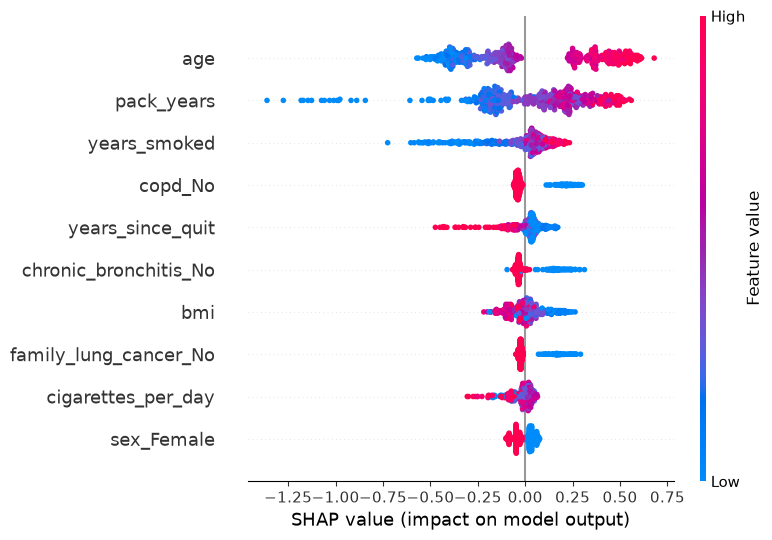

In [16]:
explainer = shap.TreeExplainer(lgb_model)
sample_idx = np.random.choice(len(X_test_proc), size=500, replace=False)
X_test_sample = X_test_proc[sample_idx]

shap_values = explainer.shap_values(X_test_sample)
if isinstance(shap_values, list):
    shap_vals = shap_values[1]
else:
    shap_vals = shap_values

mean_shap = np.abs(shap_vals).mean(axis=0)
top_features = pd.Series(mean_shap, index=all_feature_names).sort_values(ascending=False)

print("Top 10 Global Features by Mean |SHAP| Attribution:")
print(top_features.head(10).round(4))

shap.summary_plot(shap_vals, X_test_sample, feature_names=all_feature_names, max_display=10, show=True)


In [ ]:
sample_patient = {
    "age": 65,
    "sex": "Male",
    "race": "White",
    "education": "High School",
    "bmi": 28.5,
    "smoking_status": "Current",
    "cigarettes_per_day": 20,
    "years_smoked": 40,
    "pack_years": 40.0,
    "years_since_quit": 0,
    "copd": "Yes",
    "emphysema": "No",
    "chronic_bronchitis": "No",
    "personal_cancer_history": "No",
    "family_lung_cancer": "No",
    "occupational_exposure": "None",
    "secondhand_smoke": "No",
    "alcohol_use": "Moderate",
    "screening_history": "None"
}

sample_df = pd.DataFrame([sample_patient])
sample_proc = preprocessor.transform(sample_df)

lr_coef = lr.coef_[0]
lr_contribs = sample_proc[0] * lr_coef
lr_z = np.sum(lr_contribs) + lr.intercept_[0]

lgb_z = lgb_model.predict(sample_proc, raw_score=True)[0]
lgb_shap = explainer.shap_values(sample_proc)
if isinstance(lgb_shap, list):
    lgb_shap = lgb_shap[1]
lgb_shap_contribs = lgb_shap[0]

hybrid_z = HYBRID_WEIGHT_LR * lr_z + (1.0 - HYBRID_WEIGHT_LR) * lgb_z
hybrid_prob = float(1.0 / (1.0 + np.exp(-hybrid_z)))
risk_level = "HIGH" if hybrid_prob >= DECISION_THRESHOLD else "MEDIUM" if hybrid_prob >= 0.35 else "LOW"

hybrid_contribs = HYBRID_WEIGHT_LR * lr_contribs + (1.0 - HYBRID_WEIGHT_LR) * lgb_shap_contribs
top_idx = np.argsort(np.abs(hybrid_contribs))[::-1][:5]

structured_evidence = {
    "patient_id": "PT_SAMPLE_001",
    "risk_probability": round(hybrid_prob, 4),
    "risk_level": risk_level,
    "threshold": DECISION_THRESHOLD,
    "top_contributors": [
        {
            "feature": all_feature_names[i],
            "contribution": round(float(hybrid_contribs[i]), 4),
            "direction": "INCREASE" if hybrid_contribs[i] > 0 else "DECREASE"
        }
        for i in top_idx
    ]
}

print(json.dumps(structured_evidence, indent=2))


{
  "patient_id": "PT_SAMPLE_001",
  "risk_probability": 0.5311,
  "risk_level": "MEDIUM",
  "threshold": 0.67,
  "top_contributors": [
    {
      "feature": "copd_Yes",
      "contribution": 0.224,
      "direction": "INCREASE"
    },
    {
      "feature": "chronic_bronchitis_No",
      "contribution": -0.137,
      "direction": "DECREASE"
    },
    {
      "feature": "years_since_quit",
      "contribution": 0.1252,
      "direction": "INCREASE"
    },
    {
      "feature": "family_lung_cancer_No",
      "contribution": -0.1122,
      "direction": "DECREASE"
    },
    {
      "feature": "pack_years",
      "contribution": 0.1095,
      "direction": "INCREASE"
    }
  ]
}


In [18]:
GENAI_SYSTEM_PROMPT = """You are a lung-cancer risk communication assistant for the PulmoGuard AI system.
You will receive structured model evidence for one patient.

STRICT GROUNDING RULES — FOLLOW EXACTLY:
1. Use ONLY the information provided in the structured evidence below.
2. Do NOT change the risk_probability value. Report it exactly as given.
3. Do NOT change the risk_level. Report it exactly as given (LOW / MEDIUM / HIGH).
4. Do NOT invent any patient information not present in the evidence.
5. Do NOT introduce risk factors that are not listed in top_contributors.
6. Do NOT diagnose cancer. Never state the patient has or does not have cancer.
7. Describe contributing factors as "model contributions" from the hybrid ML model.
8. Provide only general awareness recommendations, not clinical advice.
9. Clearly state that this result is a machine-learning risk estimate, NOT a medical diagnosis.
10. Recommend consultation with a qualified healthcare professional for any medical decision.

PATIENT EVIDENCE:
{evidence}
"""

formatted_prompt = GENAI_SYSTEM_PROMPT.replace("{evidence}", json.dumps(structured_evidence, indent=2))
print("Constructed Grounded GenAI Prompt:")
print("-" * 50)
print(formatted_prompt)
print("-" * 50)


Constructed Grounded GenAI Prompt:
--------------------------------------------------
You are a lung-cancer risk communication assistant for the PulmoGuard AI system.
You will receive structured model evidence for one patient.

STRICT GROUNDING RULES — FOLLOW EXACTLY:
1. Use ONLY the information provided in the structured evidence below.
2. Do NOT change the risk_probability value. Report it exactly as given.
3. Do NOT change the risk_level. Report it exactly as given (LOW / MEDIUM / HIGH).
4. Do NOT invent any patient information not present in the evidence.
5. Do NOT introduce risk factors that are not listed in top_contributors.
6. Do NOT diagnose cancer. Never state the patient has or does not have cancer.
7. Describe contributing factors as "model contributions" from the hybrid ML model.
8. Provide only general awareness recommendations, not clinical advice.
9. Clearly state that this result is a machine-learning risk estimate, NOT a medical diagnosis.
10. Recommend consultation w

In [19]:
ARTIFACT_DIR = "pulmogard_artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

joblib.dump(preprocessor, os.path.join(ARTIFACT_DIR, "preprocessor.pkl"))
joblib.dump(lr, os.path.join(ARTIFACT_DIR, "lr_model.pkl"))
joblib.dump(lgb_model, os.path.join(ARTIFACT_DIR, "lgb_model.pkl"))
joblib.dump({"hybrid_weight_lr": HYBRID_WEIGHT_LR}, os.path.join(ARTIFACT_DIR, "hybrid_weight.pkl"))
joblib.dump({"threshold": DECISION_THRESHOLD}, os.path.join(ARTIFACT_DIR, "threshold.pkl"))
joblib.dump(all_feature_names, os.path.join(ARTIFACT_DIR, "feature_names.pkl"))

with open(os.path.join(ARTIFACT_DIR, "model_metrics.json"), "w") as f:
    json.dump({k: round(float(v), 4) for k, v in metrics.items()}, f, indent=2)

print(f"All production artifacts successfully serialized to '{ARTIFACT_DIR}/':")
for fname in os.listdir(ARTIFACT_DIR):
    print(f"  ✓ {fname}")


All production artifacts successfully serialized to 'pulmogard_artifacts/':
  ✓ model_metrics.json
  ✓ preprocessor.pkl
  ✓ lgb_model.pkl
  ✓ model_metrics.pkl
  ✓ lr_model.pkl
  ✓ genai_prompts.json
  ✓ feature_names.pkl
  ✓ config.json
  ✓ test_predictions.csv
  ✓ threshold.pkl
  ✓ structured_evidence.json
  ✓ shap_data.pkl
  ✓ final_report.txt
  ✓ hybrid_weight.pkl
